In [4]:
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
# matplotlib.rcParams['font.family'] = 'AppleGothic'
matplotlib.rcParams['axes.unicode_minus']=False
import pandas as pd
from sklearn import svm,metrics
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor 
from sklearn.metrics import mean_absolute_error # 평균절대값오차 오차범위
from sklearn.preprocessing import StandardScaler# 정규화 클래스
from sklearn.model_selection import train_test_split
import numpy as np
from io import StringIO

In [5]:
perch_length = np.array(
    [8.4, 13.7, 15.0, 16.2, 17.4, 18.0, 18.7, 19.0, 19.6, 20.0,
    21.0, 21.0, 21.0, 21.3, 22.0, 22.0, 22.0, 22.0, 22.0, 22.5,
    22.5, 22.7, 23.0, 23.5, 24.0, 24.0, 24.6, 25.0, 25.6, 26.5,
    27.3, 27.5, 27.5, 27.5, 28.0, 28.7, 30.0, 32.8, 34.5, 35.0,
    36.5, 36.0, 37.0, 37.0, 39.0, 39.0, 39.0, 40.0, 40.0, 40.0,
    40.0, 42.0, 43.0, 43.0, 43.5, 44.0]
    )
perch_weight = np.array(
    [5.9, 32.0, 40.0, 51.5, 70.0, 100.0, 78.0, 80.0, 85.0, 85.0,
    110.0, 115.0, 125.0, 130.0, 120.0, 120.0, 130.0, 135.0, 110.0,
    130.0, 150.0, 145.0, 150.0, 170.0, 225.0, 145.0, 188.0, 180.0,
    197.0, 218.0, 300.0, 260.0, 265.0, 250.0, 250.0, 300.0, 320.0,
    514.0, 556.0, 840.0, 685.0, 700.0, 700.0, 690.0, 900.0, 650.0,
    820.0, 850.0, 900.0, 1015.0, 820.0, 1100.0, 1000.0, 1100.0,
    1000.0, 1000.0]
    )

In [12]:
train_data,test_data,train_label,test_label = train_test_split(perch_length,perch_weight)
train_data = train_data.reshape(-1,1)
test_data = test_data.reshape(-1,1)

In [14]:
# 다항회귀
# train_dat [[43.5**2,43.5]]
train_poly = np.column_stack((train_data**2,train_data))
test_poly = np.column_stack((test_data**2,test_data))

In [16]:
# 데이터 학습
lr = LinearRegression()
lr.fit(train_poly,train_label)

# 데이터 예측
predict = lr.predict(train_poly)
print('무게예측:',predict)
# 정확도
score = lr.score(train_poly,train_label)
score2 = lr.score(test_poly,test_label)
score,score2

무게예측: [ 888.66501508  116.84234823   56.84079727  110.44300332  291.39518295
  688.366416    132.50888738  182.93837856  715.40607082   90.47636028
   83.07749055   67.65808966  132.50888738 1149.06631507  334.50023271
  211.30198568  828.81279264   22.13176042  132.50888738  715.40607082
 1114.67931668  308.98825317  384.60863661  182.93837856  229.32778564
   12.95855644  888.66501508  132.50888738  199.70463391  149.20405463
 1014.66718303  661.85157144  504.58407309  828.81279264   72.60895827
  291.39518295  610.39631308  144.32904479  132.50888738  257.78347328
   12.27583491   33.74819486]


(0.9703752842557495, 0.9731363233066878)

In [26]:
i = 25
result = lr.predict([[i**2,i]])
result

array([211.30198568])

In [29]:
point = np.arange(15,50)
point

array([15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31,
       32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48,
       49])

[  1.04962051 -23.0677979 ] 131.98411405472183


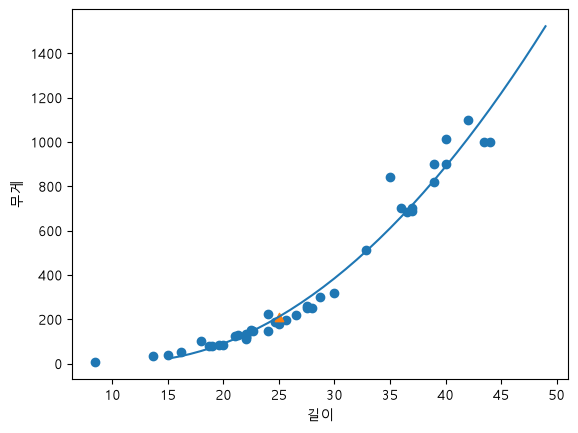

In [28]:
# 그래프
print(lr.coef_,lr.intercept_)

plt.scatter(train_data,train_label)
plt.scatter(25,211.3,marker='^')
plt.plot(point,lr.coef_[0]*point**2+lr.coef_[1]*point+lr.intercept_)
plt.xlabel('길이')
plt.ylabel('무게')
plt.show()